# 05 · Calibrer les probabilités et choisir le seuil

**Étape 8** (slides 39–44) puis **étape 9** (slides 18, 44) du cas pratique.

Deux clients ont besoin de probabilités **justes**, pas seulement bien ordonnées : KaziPay, dont le seuil théorique $t^* = C_{FP} / (C_{FP} + C_{FN}) \approx 0{,}091$ n'a de sens que si les probabilités sont calibrées, et la banque centrale, qui estime le nombre de personnes qui ont un compte bancaire par la **somme des probabilités**.

On travaille uniquement sur des **prédictions hors pli** (out-of-fold) du train : chaque ligne est prédite par un modèle qui ne l'a pas vue. Le test reste scellé.

In [1]:
%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import cross_val_predict

from financial_inclusion_africa import config, models, viz
from financial_inclusion_africa.data import load_split
from financial_inclusion_africa.evaluate import (CV, T_STAR, calibration_metrics, ece_noise_floor,
                                                 expected_counts, reliability_table)
from financial_inclusion_africa.features import pipe

viz.set_style()
pd.set_option("display.precision", 4)
RS = config.RANDOM_STATE
X_train, X_test, y_train, y_test = load_split()  # X_test : non utilisé avant l'étape 10
print(f"t* = {T_STAR:.4f}")

t* = 0.0909


## Étape 8 · Calibrer les probabilités

### 8.1 Mesurer

Les trois modèles retenus à l'étape 7 (`models.CANDIDATES`), plus deux forêts aléatoires pour comparer (Q8.1) : la forêt **par défaut** (feuilles d'un individu, très surapprise à l'étape 5) et la forêt **régularisée** `min_samples_leaf=10`.

`cross_val_predict` renvoie, pour chaque ligne du train, la probabilité donnée par le modèle du pli où elle était en validation. Les métriques sont ensuite calculées sur les 18 819 prédictions regroupées : la PR-AUC peut différer de quelques millièmes de la moyenne pli par pli des étapes 6–7.

In [2]:
MODELS = {
    "Régression logistique": models.make_baseline(),
    "LightGBM réglé": models.make_lgbm(),
    "CatBoost réglé": models.make_catboost(),
    "Forêt · défaut": pipe(RandomForestClassifier(300, random_state=RS, n_jobs=1), scale=False),
    "Forêt · leaf=10": pipe(RandomForestClassifier(300, min_samples_leaf=10, random_state=RS, n_jobs=1),
                            scale=False),
}
CANDIDATS = ["Régression logistique", "LightGBM réglé", "CatBoost réglé"]

oof = {}  # (modèle, version) -> probabilités hors pli
for name, model in MODELS.items():
    t0 = time.time()
    oof[(name, "brute")] = cross_val_predict(model, X_train, y_train, cv=CV, method="predict_proba",
                                             n_jobs=-1)[:, 1]
    print(f"{name:<22} {time.time() - t0:5.1f} s")

Régression logistique    1.6 s


LightGBM réglé           1.8 s


CatBoost réglé          11.7 s


Forêt · défaut           4.0 s


Forêt · leaf=10          2.9 s


**ECE** (slide 42) : dans chaque intervalle $k$ de probabilité, on compare la probabilité moyenne annoncée $\text{conf}(k)$ et la fréquence observée $\text{acc}(k)$, pondérées par la part $n_k/n$ des personnes de l'intervalle :

$$\text{ECE} = \sum_k \frac{n_k}{n}\,\lvert \text{acc}(k) - \text{conf}(k)\rvert .$$

**Plancher de bruit.** Sur un échantillon fini, l'ECE n'est jamais nulle, même pour un modèle parfait : la fréquence observée fluctue autour de la vraie probabilité. `ece_noise_floor` tire 200 fois $y \sim \text{Bernoulli}(\hat p)$, c'est-à-dire des étiquettes **parfaitement calibrées par construction** pour les mêmes probabilités, et mesure l'ECE obtenue. Une ECE sous le 95e centile de ce plancher est indiscernable du hasard.

In [3]:
def metrics_table(keys):
    rows = {f"{n} · {v}": calibration_metrics(y_train, oof[(n, v)]) for n, v in keys}
    return pd.DataFrame(rows).T

raw = metrics_table([(n, "brute") for n in MODELS])
floors = {f"{n} · brute": ece_noise_floor(oof[(n, "brute")]) for n in MODELS}
raw["ECE plancher (moy.)"] = [floors[i]["moyenne"] for i in raw.index]
raw["ECE plancher (95e c.)"] = [floors[i]["95e centile"] for i in raw.index]
print(f"Prévalence réelle : {y_train.mean():.4f}")
raw.round(4)

Prévalence réelle : 0.1408


,ECE,Brier,log-loss,PR-AUC,ROC-AUC,prévalence prédite,ECE plancher (moy.),ECE plancher (95e c.)
Régression logistique · brute,0.0059,0.0870,0.2919,0.5589,0.8490,0.1408,0.0049,0.0074
LightGBM réglé · brute,0.0047,0.0845,0.2829,0.5802,0.8610,0.1408,0.0049,0.0073
CatBoost réglé · brute,0.0053,0.0841,0.2818,0.5830,0.8628,0.1391,0.0048,0.0070
Forêt · défaut · brute,0.0583,0.1027,0.5730,0.4741,0.8041,0.1429,0.0045,0.0065
Forêt · leaf=10 · brute,0.0087,0.0857,0.2865,0.5724,0.8576,0.1407,0.0048,0.0070


### Q8.1 · Diagrammes de fiabilité

Un point par intervalle de largeur 0,1 (`n_bins=10`, comme `CalibrationDisplay`) ; les barres verticales sont l'intervalle de confiance à 95 % de la fréquence observée : peu de personnes reçoivent une probabilité élevée, les derniers points sont donc bruités. Les barres grises en bas montrent où se trouvent les personnes.

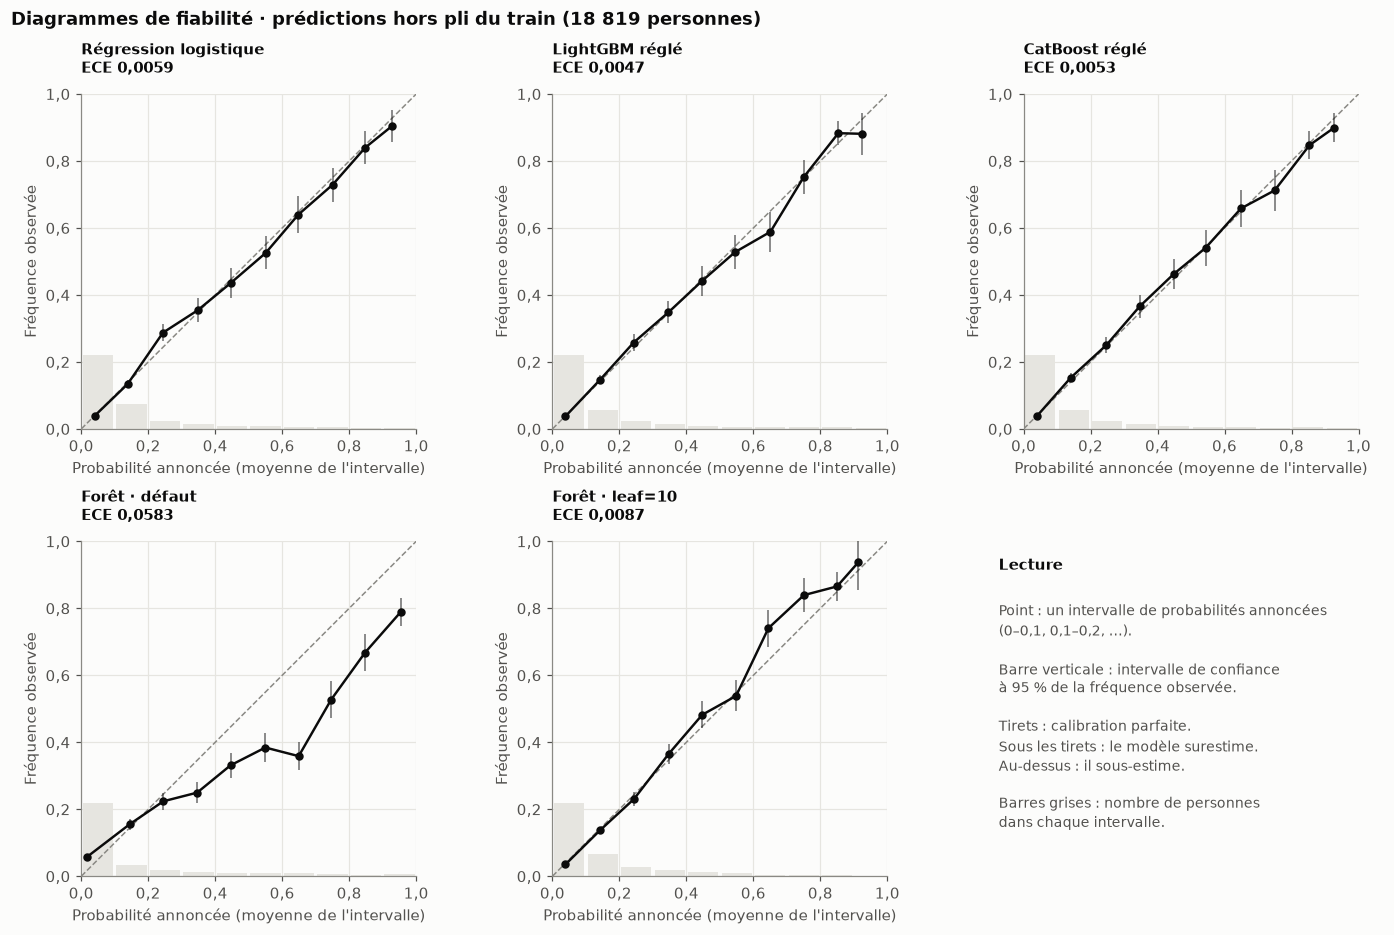

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
for ax, name in zip(axes.flat, MODELS):
    p = oof[(name, "brute")]
    viz.reliability(ax, y_train, p, hist=True)
    ece = raw.loc[f"{name} · brute", "ECE"]
    ax.set_title(f"{name}\nECE {viz.fr(f'{ece:.4f}')}", fontsize=10)
ax = axes.flat[-1]
ax.axis("off")
ax.text(0, 0.95, "Lecture", fontweight="bold", va="top", transform=ax.transAxes)
ax.text(0, 0.82,
        "Point : un intervalle de probabilités annoncées\n"
        "(0–0,1, 0,1–0,2, …).\n\n"
        "Barre verticale : intervalle de confiance\n"
        "à 95 % de la fréquence observée.\n\n"
        "Tirets : calibration parfaite.\n"
        "Sous les tirets : le modèle surestime.\n"
        "Au-dessus : il sous-estime.\n\n"
        "Barres grises : nombre de personnes\n"
        "dans chaque intervalle.",
        va="top", fontsize=9, color=viz.INK_2, transform=ax.transAxes, linespacing=1.4)
fig.suptitle("Diagrammes de fiabilité · prédictions hors pli du train (18 819 personnes)",
             x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "08_diagrammes_fiabilite")
plt.show()

In [5]:
# Écart observé − annoncé, intervalle par intervalle (en points de pourcentage) ; effectifs en dessous
gaps = pd.DataFrame({n: reliability_table(y_train, oof[(n, "brute")])["écart observé − annoncé"] * 100
                     for n in MODELS}).T
counts = pd.DataFrame({n: reliability_table(y_train, oof[(n, "brute")])["effectif"] for n in MODELS}).T
display(gaps.round(1))
counts

intervalle,[0.0 ; 0.1[,[0.1 ; 0.2[,[0.2 ; 0.3[,[0.3 ; 0.4[,[0.4 ; 0.5[,[0.5 ; 0.6[,[0.6 ; 0.7[,[0.7 ; 0.8[,[0.8 ; 0.9[,[0.9 ; 1.0[
Régression logistique,-0.1,-0.4,4.3,0.7,-1.0,-2.5,-0.8,-2.1,-0.8,-2.3
LightGBM réglé,-0.1,0.5,1.5,0.2,-0.5,-1.7,-6.2,0.2,2.9,-4.3
CatBoost réglé,-0.1,1.2,0.3,1.9,1.4,-0.3,0.9,-3.7,-0.6,-2.8
Forêt · défaut,4.0,1.1,-2.1,-9.6,-11.5,-16.5,-29.1,-21.9,-18.0,-16.5
Forêt · leaf=10,-0.4,-0.5,-1.3,1.8,3.5,-1.0,9.6,8.8,1.6,2.4


intervalle,[0.0 ; 0.1[,[0.1 ; 0.2[,[0.2 ; 0.3[,[0.3 ; 0.4[,[0.4 ; 0.5[,[0.5 ; 0.6[,[0.6 ; 0.7[,[0.7 ; 0.8[,[0.8 ; 0.9[,[0.9 ; 1.0[
Régression logistique,11358,3792,1155,703,489,394,289,288,206,145
LightGBM réglé,11914,3040,1217,798,496,377,265,286,325,101
CatBoost réglé,11976,3062,1247,760,467,346,284,212,275,190
Forêt · défaut,12606,1856,1041,757,628,484,488,326,277,356
Forêt · leaf=10,11241,3445,1459,936,583,442,243,193,245,32


**Réponse Q8.1.** On lit l'écart *observé − annoncé* : négatif = le modèle **surestime**, positif = il **sous-estime**. Il faut le comparer à la largeur des barres d'erreur : au-delà de 0,5, un intervalle ne compte que quelques centaines de personnes et l'intervalle de confiance fait ± 4 à 10 points.

- **Régression logistique** (ECE 0,006) : sur la diagonale, sauf l'intervalle 0,2–0,3 où elle **sous-estime** (annonce 24,4 %, observé 28,7 % sur 1 155 personnes) ; au-dessus de 0,5 elle surestime légèrement (−0,8 à −2,5 points), dans les barres d'erreur.
- **LightGBM réglé** (0,005) : sur la diagonale jusqu'à 0,6 ; surestime un peu en haut (0,6–0,7 : 65 % annoncé, 59 % observé ; 0,9–1 : −4 points), sur 100 à 300 personnes.
- **CatBoost réglé** (0,005) : sous-estime d'un ou deux points entre 0,1 et 0,5, surestime de 1 à 4 points au-dessus de 0,7. Tout reste dans les barres d'erreur.
- **Forêt par défaut** (0,058, dix fois plus) : **trop sûre d'elle aux deux bouts**. Elle annonce 1,8 % à 12 606 personnes dont 5,8 % ont un compte (**sous-estime** en bas), et **surestime** tout ce qui dépasse 0,3 : 65 % annoncé pour 36 % observé, 95 % pour 79 %. Des arbres complets (feuilles d'une personne) apprennent le train par cœur (PR-AUC d'entraînement 0,986 à l'étape 5) : leurs votes sont trop unanimes.
- **Forêt leaf=10** (0,009) : le motif de la slide 41, inverse. Elle **sous-estime en haut** (annonce 65 % et 75 %, observé 74 % et 84 %) : une moyenne de votes d'arbres rarement unanimes reste loin de 0 et de 1.

Pour les trois candidats, l'ECE (0,0047 à 0,0059) est **dans le plancher de bruit** (moyenne ≈ 0,005, 95e centile 0,007) : on ne distingue pas leurs écarts du hasard. Seules les deux forêts dépassent le plancher : elles sont réellement mal calibrées.

### 8.2 Corriger : Platt et isotone

`CalibratedClassifierCV(cv=5)` découpe chaque train de pli extérieur en 5 : le modèle est entraîné sur 4/5, la fonction de calibration apprise sur les prédictions du 1/5 restant ; les 5 couples (modèle, calibrateur) sont moyennés. Le `CV` extérieur de `cross_val_predict` mesure le résultat : **deux niveaux de validation croisée** s'emboîtent.

- **Platt** (`sigmoid`) : $p = 1/(1 + e^{A s + B})$, deux paramètres.
- **Isotone** : $p = g(s)$, $g$ croissante en escalier, sans forme imposée.

In [6]:
METHODS = {"Platt": "sigmoid", "isotone": "isotonic"}
for name, model in MODELS.items():
    for label, method in METHODS.items():
        t0 = time.time()
        cal = CalibratedClassifierCV(model, method=method, cv=5)
        oof[(name, label)] = cross_val_predict(cal, X_train, y_train, cv=CV, method="predict_proba",
                                               n_jobs=-1)[:, 1]
        print(f"{name:<22} {label:<8} {time.time() - t0:5.1f} s")

Régression logistique  Platt      1.2 s


Régression logistique  isotone    1.2 s


LightGBM réglé         Platt      3.3 s


LightGBM réglé         isotone    3.4 s


CatBoost réglé         Platt     46.6 s


CatBoost réglé         isotone   47.3 s


Forêt · défaut         Platt     18.1 s


Forêt · défaut         isotone   19.2 s


Forêt · leaf=10        Platt     13.2 s


Forêt · leaf=10        isotone   12.9 s


### Q8.2 · ECE et Brier avant et après calibration

In [7]:
versions = ["brute", "Platt", "isotone"]
cal_table = metrics_table([(n, v) for n in MODELS for v in versions])
cal_table[["ECE", "Brier", "log-loss", "PR-AUC", "ROC-AUC", "prévalence prédite"]].round(4)

,ECE,Brier,log-loss,PR-AUC,ROC-AUC,prévalence prédite
Régression logistique · brute,0.0059,0.0870,0.2919,0.5589,0.8490,0.1408
Régression logistique · Platt,0.0068,0.0870,0.2918,0.5589,0.8491,0.1408
Régression logistique · isotone,0.0034,0.0870,0.2951,0.5567,0.8488,0.1409
LightGBM réglé · brute,0.0047,0.0845,0.2829,0.5802,0.8610,0.1408
LightGBM réglé · Platt,0.0047,0.0846,0.2834,0.5794,0.8603,0.1409
LightGBM réglé · isotone,0.0040,0.0847,0.2900,0.5784,0.8599,0.1407
CatBoost réglé · brute,0.0053,0.0841,0.2818,0.5830,0.8628,0.1391
CatBoost réglé · Platt,0.0255,0.0858,0.2932,0.5825,0.8623,0.1409
CatBoost réglé · isotone,0.0048,0.0842,0.2853,0.5806,0.8621,0.1409
Forêt · défaut · brute,0.0583,0.1027,0.5730,0.4741,0.8041,0.1429


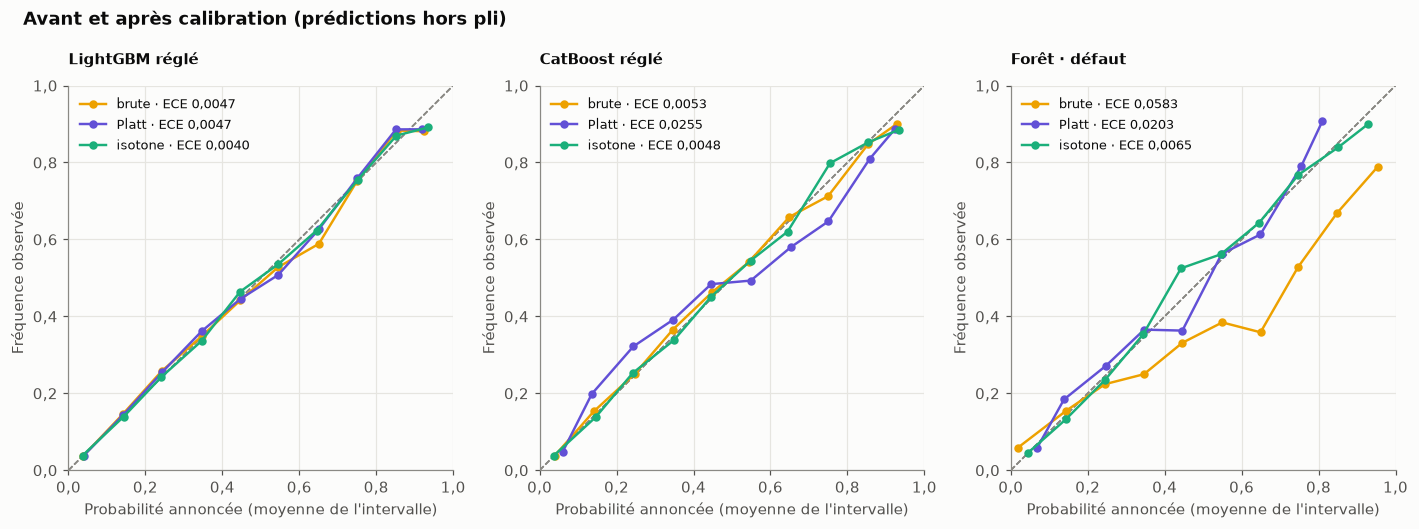

In [8]:
VERSION_COLORS = {"brute": viz.COMPOSITION[2], "Platt": viz.COMPOSITION[1], "isotone": viz.COMPOSITION[0]}
shown = ["LightGBM réglé", "CatBoost réglé", "Forêt · défaut"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, name in zip(axes, shown):
    for v in versions:
        ece = cal_table.loc[f"{name} · {v}", "ECE"]
        viz.reliability(ax, y_train, oof[(name, v)], color=VERSION_COLORS[v], ci=False,
                        label=f"{v} · ECE {viz.fr(f'{ece:.4f}')}")
    ax.set_title(name, fontsize=10)
    ax.legend(loc="upper left", fontsize=8.5)
fig.suptitle("Avant et après calibration (prédictions hors pli)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "08_platt_isotone")
plt.show()

Platt **dégrade** CatBoost et la forêt leaf=10, alors qu'il est neutre pour la régression logistique et LightGBM. Pourquoi ? Le score $s$ que Platt reçoit n'est pas le même :

In [9]:
pd.Series({n: "decision_function (log-odds)" if hasattr(MODELS[n], "decision_function")
           else "predict_proba (probabilité)" for n in MODELS}, name="score s reçu par Platt").to_frame()

,score s reçu par Platt
Régression logistique,decision_function (log-odds)
LightGBM réglé,decision_function (log-odds)
CatBoost réglé,predict_proba (probabilité)
Forêt · défaut,predict_proba (probabilité)
Forêt · leaf=10,predict_proba (probabilité)


In [10]:
# Démonstration sur les probabilités hors pli de CatBoost : une sigmoïde de p, ou du log-odds de p ?
p_cat = oof[("CatBoost réglé", "brute")]
logit = np.log(p_cat / (1 - p_cat))
demo = {}
for label, s in {"sigmoïde de p (ce que fait scikit-learn)": p_cat,
                 "sigmoïde de logit(p)": logit}.items():
    p_platt = cross_val_predict(LogisticRegression(), s.reshape(-1, 1), y_train, cv=CV,
                                method="predict_proba")[:, 1]
    demo[label] = calibration_metrics(y_train, p_platt)
pd.DataFrame(demo).T[["ECE", "Brier", "log-loss"]].round(4)

,ECE,Brier,log-loss
sigmoïde de p (ce que fait scikit-learn),0.0258,0.0859,0.2939
sigmoïde de logit(p),0.0047,0.0841,0.2819


**Réponse Q8.2.**

| | ECE brute | Platt | isotone | Brier brut → isotone | log-loss brute → isotone |
|---|---|---|---|---|---|
| Régression logistique | 0,0059 | 0,0068 | 0,0034 | 0,0870 → 0,0870 | 0,292 → 0,295 |
| LightGBM réglé | 0,0047 | 0,0047 | 0,0040 | 0,0845 → 0,0847 | 0,283 → 0,290 |
| CatBoost réglé | 0,0053 | **0,0255** | 0,0048 | 0,0841 → 0,0842 | 0,282 → 0,285 |
| Forêt · défaut | **0,0583** | 0,0203 | **0,0065** | 0,1027 → 0,0940 | 0,573 → 0,316 |
| Forêt · leaf=10 | 0,0087 | 0,0209 | 0,0041 | 0,0857 → 0,0857 | 0,287 → 0,293 |

- **Pour nos candidats, la calibration n'est pas nécessaire.** Leur ECE brute est déjà dans le plancher de bruit. L'isotone la baisse un peu (de 0,0005 à 0,0025), sans changer le Brier, mais **augmente la log-loss** (+0,003 à +0,007) et **baisse la PR-AUC** (Q8.3). C'est une couche de plus, apprise sur 4/5 des données, pour un gain invisible.
- **Platt peut nuire.** CatBoost et la forêt n'ont pas de `decision_function` : scikit-learn applique la sigmoïde à leur **probabilité** $p$. Or $1/(1 + e^{A p + B})$ ne peut pas reproduire l'identité : à $p = 0$ elle vaut $1/(1 + e^B)$, et elle déforme en S une sortie déjà juste (ECE de CatBoost × 5). Appliquée au log-odds de $p$, la même sigmoïde redevient inoffensive (démonstration ci-dessus). La régression logistique et LightGBM fournissent leur log-odds, Platt y est presque l'identité.
- **Pour la forêt par défaut, la calibration est indispensable** : l'isotone divise l'ECE par 9 et la log-loss presque par 2 : c'est le cas de la slide 41.

**Pourquoi un boosting entraîné sur la log-loss est-il souvent déjà calibré ?** La log-loss est une **règle de score propre** : son espérance est minimale quand la probabilité annoncée est la vraie probabilité. Le boosting la minimise directement : chaque feuille reçoit la valeur (pas de Newton) qui annule, à la pénalité L2 près, la somme des résidus $y - p$ des personnes de la feuille. Dans chaque région, la probabilité moyenne annoncée rejoint donc la fréquence observée. La régression logistique a la même propriété (équations du maximum de vraisemblance : $\sum_i (y_i - p_i)\,x_i = 0$). Ce qui la casse (slide 44) : le **surapprentissage** (scores trop proches de 0 et 1), une régularisation ou un arrêt anticipé forts (scores tirés vers la moyenne), le sous-échantillonnage, et tout **rééquilibrage des classes** (`class_weight`, SMOTE). Les forêts, elles, n'optimisent aucune règle propre : elles moyennent des votes.

### Q8.3 · La calibration change-t-elle la PR-AUC et la ROC-AUC ?

In [11]:
delta = pd.DataFrame({
    f"{n} · {v}": {
        "Δ PR-AUC": cal_table.loc[f"{n} · {v}", "PR-AUC"] - cal_table.loc[f"{n} · brute", "PR-AUC"],
        "Δ ROC-AUC": cal_table.loc[f"{n} · {v}", "ROC-AUC"] - cal_table.loc[f"{n} · brute", "ROC-AUC"],
        "valeurs distinctes": len(np.unique(oof[(n, v)].round(12))),
    }
    for n in MODELS for v in versions
}).T
delta["valeurs distinctes"] = delta["valeurs distinctes"].astype(int)
delta.round(4)

,Δ PR-AUC,Δ ROC-AUC,valeurs distinctes
Régression logistique · brute,0.0000,0.0000,17592
Régression logistique · Platt,-0.0000,0.0001,17592
Régression logistique · isotone,-0.0022,-0.0002,3884
LightGBM réglé · brute,0.0000,0.0000,17386
LightGBM réglé · Platt,-0.0008,-0.0007,17591
LightGBM réglé · isotone,-0.0018,-0.0011,6689
CatBoost réglé · brute,0.0000,0.0000,17301
CatBoost réglé · Platt,-0.0005,-0.0006,17577
CatBoost réglé · isotone,-0.0025,-0.0008,5920
Forêt · défaut · brute,0.0000,0.0000,3632


In [12]:
# Une transformation strictement croissante ne change pas l'ordre, donc pas les AUC
p = oof[("CatBoost réglé", "brute")]
for f_name, f in {"p": p, "√p": np.sqrt(p), "sigmoïde(3·logit p − 1)": 1 / (1 + np.exp(-(3 * np.log(p / (1 - p)) - 1)))}.items():
    print(f"{f_name:<24} PR-AUC {average_precision_score(y_train, f):.6f}   ROC-AUC {roc_auc_score(y_train, f):.6f}")
share_zero = (oof[("Forêt · défaut", "brute")] == 0).mean()
print(f"\nForêt par défaut : {share_zero:.1%} des personnes reçoivent une probabilité exactement nulle")

p                        PR-AUC 0.583043   ROC-AUC 0.862836
√p                       PR-AUC 0.583043   ROC-AUC 0.862836
sigmoïde(3·logit p − 1)  PR-AUC 0.583043   ROC-AUC 0.862836

Forêt par défaut : 26.4% des personnes reçoivent une probabilité exactement nulle


**Réponse Q8.3. Presque pas, et c'est voulu** (slide 40 : l'AUC juge l'ordre des scores, la calibration juge leur valeur). Une fonction **strictement croissante** ne change pas l'ordre, donc ni la PR-AUC ni la ROC-AUC : les trois transformations ci-dessus donnent exactement les mêmes AUC. Les petits écarts observés ont deux causes :

1. **L'isotone est en escalier** : elle n'est que croissante au sens large. Toutes les personnes d'une même marche reçoivent la même probabilité, l'ordre entre elles est perdu (17 301 valeurs distinctes pour CatBoost brut, 5 920 après isotone) : PR-AUC −0,002 à −0,004.
2. **`CalibratedClassifierCV` est un autre modèle** : la moyenne de 5 copies entraînées chacune sur 4/5 des lignes. L'ordre des scores change un peu, même avec Platt.

La forêt par défaut fait exception : sa PR-AUC **monte** (+0,02), avec Platt comme avec l'isotone. Ce n'est pas la calibration qui la sauve, mais la moyenne de 5 forêts. La forêt brute ne prend que 3 632 valeurs distinctes et donne une probabilité exactement nulle à 26 % des personnes : ces ex-aequo sont impossibles à classer entre eux. La moyenne de 5 forêts les départage en partie (plus de 10 000 valeurs distinctes).

### 8.3 Compter les personnes qui ont un compte bancaire (Q8.4)

La banque centrale estime, par pays, le nombre de personnes qui ont un compte bancaire par $\sum_i \hat p_i$ (slide 40). Même avec des probabilités parfaites, le nombre réel varie autour de cette somme : c'est une somme de Bernoulli, d'écart-type $\sqrt{\sum_i \hat p_i (1 - \hat p_i)}$. La colonne `écart / écart-type` mesure l'écart en unités de ce bruit : au-delà de 2 en valeur absolue, c'est un biais.

In [13]:
COUNT_MODELS = CANDIDATS + ["Forêt · leaf=10"]
agg = pd.concat({n: expected_counts(y_train, oof[(n, "brute")], X_train["country"]) for n in COUNT_MODELS},
                names=["modèle", "pays"])
agg.round(3)

réel   attendu   écart  erreur relative  \
modèle                pays                                                  
Régression logistique Kenya     1207.0  1206.412  -0.588           -0.000   
                      Rwanda     808.0   807.778  -0.222           -0.000   
                      Tanzania   490.0   490.583   0.583            0.001   
                      Uganda     145.0   145.467   0.467            0.003   
                      Total     2650.0  2650.239   0.239            0.000   
LightGBM réglé        Kenya     1207.0  1204.398  -2.602           -0.002   
                      Rwanda     808.0   801.878  -6.122           -0.008   
                      Tanzania   490.0   493.910   3.910            0.008   
                      Uganda     145.0   149.618   4.618            0.032   
                      Total     2650.0  2649.804  -0.196           -0.000   
CatBoost réglé        Kenya     1207.0  1181.238 -25.762           -0.021   
                      Rwanda     808.0   799.672  -8.328           -0.010   
                      Tanzania   490.0   488.775  -1.225           -0.003   
                      Uganda     145.0   148.640   3.640            0.025   
                      Total     2650.0  2618.325 -31.675           -0.012   
Forêt · leaf=10       Kenya     1207.0  1154.180 -52.820           -0.044   
                      Rwanda     808.0   783.713 -24.287           -0.030   
                      Tanzania   490.0   523.163  33.163            0.068   
                      Uganda     145.0   187.504  42.504            0.293   
                      Total     2650.0  2648.561  -1.439           -0.001   

                                écart-type attendu  écart / écart-type  
modèle                pays                                              
Régression logistique Kenya                 24.631              -0.024  
                      Rwanda                24.098              -0.009  
                      Tanzania              17.933               0.032  
                      Uganda                10.430               0.045  
                      Total                 40.222               0.006  
LightGBM réglé        Kenya                 24.920              -0.104  
                      Rwanda                23.647              -0.259  
                      Tanzania              17.204               0.227  
                      Uganda                10.231               0.451  
                      Total                 39.759              -0.005  
CatBoost réglé        Kenya                 24.952              -1.032  
                      Rwanda                23.487              -0.355  
                      Tanzania              16.825              -0.073  
                      Uganda                10.088               0.361  
                      Total                 39.485              -0.802  
Forêt · leaf=10       Kenya                 25.604              -2.063  
                      Rwanda                23.930              -1.015  
                      Tanzania              17.984               1.844  
                      Uganda                11.489               3.700  
                      Total                 41.032              -0.035

In [14]:
# CatBoost après isotone, pour comparaison
expected_counts(y_train, oof[("CatBoost réglé", "isotone")], X_train["country"]).round(3)

,réel,attendu,écart,erreur relative,écart-type attendu,écart / écart-type
Kenya,1207.0,1205.291,-1.709,-0.001,25.198,-0.068
Rwanda,808.0,816.694,8.694,0.011,23.646,0.368
Tanzania,490.0,480.982,-9.018,-0.018,16.660,-0.541
Uganda,145.0,149.470,4.470,0.031,10.096,0.443
Total,2650.0,2652.437,2.437,0.001,39.668,0.061


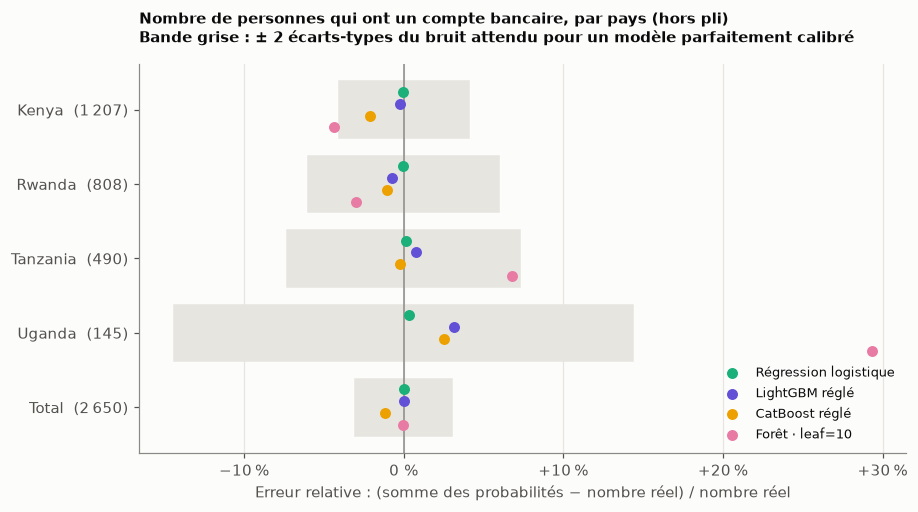

In [15]:
order = ["Kenya", "Rwanda", "Tanzania", "Uganda", "Total"]
fig, ax = plt.subplots(figsize=(9, 4.6))
ref = agg.loc["Régression logistique"]
band = 2 * ref["écart-type attendu"] / ref["réel"]
for i, g in enumerate(order):
    ax.add_patch(plt.Rectangle((-band[g], i - 0.38), 2 * band[g], 0.76, color=viz.GRID, zorder=0))
offsets = np.linspace(-0.24, 0.24, len(COUNT_MODELS))
for k, (name, off) in enumerate(zip(COUNT_MODELS, offsets)):
    err = agg.loc[name].loc[order, "erreur relative"]
    ax.scatter(err, np.arange(len(order)) + off, color=viz.COMPOSITION[k], s=38, zorder=3, label=name)
ax.axvline(0, color=viz.INK_3, lw=1)
labels = [f"{g}  ({viz.fmt_int(ref.loc[g, 'réel'])})" for g in order]
ax.set_yticks(range(len(order)), labels)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(
    lambda v, _: "0 %" if abs(v) < 1e-9 else viz.fr(f"{v:+.0%}").replace("-", "−")))
ax.set_xlabel("Erreur relative : (somme des probabilités − nombre réel) / nombre réel")
ax.set_title("Nombre de personnes qui ont un compte bancaire, par pays (hors pli)\n"
             "Bande grise : ± 2 écarts-types du bruit attendu pour un modèle parfaitement calibré",
             fontsize=10)
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(axis="y", visible=False)
viz.save(fig, "08_comptes_par_pays")
plt.show()

**Réponse Q8.4.**

- **La régression logistique sert le mieux la banque centrale** : par pays, la somme de ses probabilités tombe à moins d'une personne du nombre réel (|écart / écart-type| ≤ 0,05). Ce n'est pas un hasard : avec une colonne indicatrice par pays, les équations du maximum de vraisemblance imposent $\sum_{i \in \text{pays}} (y_i - p_i) \approx 0$ sur le train (à la pénalité près), et la propriété se transmet hors pli.
- **LightGBM et CatBoost** sont aussi utilisables : tous leurs écarts restent dans le bruit attendu (|écart / écart-type| ≤ 1,04). CatBoost sous-estime un peu le total (−32 personnes, −1,2 %, surtout au Kenya), ce qui reste compatible avec le hasard (≈ −0,8 écart-type) ; l'isotone ramène le total à +2.
- **La forêt leaf=10 est biaisée** : **+29 % en Ouganda** (188 attendus pour 145, 3,7 écarts-types) et −4 % au Kenya (−2,1 écarts-types). Ses feuilles mélangent les pays et tirent chacun vers la prévalence moyenne. Une ECE globale correcte (0,009) cache donc un biais par sous-groupe : **il faut vérifier la calibration groupe par groupe**.
- **L'erreur relative la plus grande est en Ouganda** pour chaque modèle : c'est le pays où le nombre réel est le plus petit (145). Une même erreur absolue y pèse plus, et le bruit seul y vaut déjà ± 7 % (un écart-type).

**Limite.** Ces chiffres valent pour les pays **présents à l'entraînement**. À l'étape 4, un pays absent du train était très mal estimé (Ouganda : 19,1 % prédits pour 8,9 % réels). La banque centrale ne doit pas appliquer le modèle à un cinquième pays sans données de ce pays.

### Q8.5 · Sur quelles données la calibration est-elle apprise ?

Expérience : on apprend la fonction isotone **sur les lignes qui ont entraîné le modèle**, puis on l'applique au pli de validation, et on compare à `CalibratedClassifierCV`, qui l'apprend sur des lignes que le modèle n'a pas vues.

In [16]:
def calibrate_on_train_rows(model, X, y, cv=CV):
    """Contre-exemple : fonction isotone apprise sur les prédictions du modèle sur ses propres
    lignes d'entraînement, appliquée au pli de validation."""
    p = np.zeros(len(y))
    for tr, va in cv.split(X, y):
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
        iso.fit(fitted.predict_proba(X.iloc[tr])[:, 1], y.iloc[tr])
        p[va] = iso.predict(fitted.predict_proba(X.iloc[va])[:, 1])
    return p

for name in ["Régression logistique", "LightGBM réglé", "Forêt · défaut"]:
    oof[(name, "isotone sur le train")] = calibrate_on_train_rows(MODELS[name], X_train, y_train)

q85 = metrics_table([(n, v) for n in ["Régression logistique", "LightGBM réglé", "Forêt · défaut"]
                     for v in ["brute", "isotone", "isotone sur le train"]])
q85[["ECE", "Brier", "log-loss", "PR-AUC"]].round(4)

,ECE,Brier,log-loss,PR-AUC
Régression logistique · brute,0.0059,0.0870,0.2919,0.5589
Régression logistique · isotone,0.0034,0.0870,0.2951,0.5567
Régression logistique · isotone sur le train,0.0030,0.0871,0.2990,0.5502
LightGBM réglé · brute,0.0047,0.0845,0.2829,0.5802
LightGBM réglé · isotone,0.0040,0.0847,0.2900,0.5784
LightGBM réglé · isotone sur le train,0.0078,0.0848,0.2956,0.5748
Forêt · défaut · brute,0.0583,0.1027,0.5730,0.4741
Forêt · défaut · isotone,0.0065,0.0940,0.3161,0.4969
Forêt · défaut · isotone sur le train,0.1073,0.1225,1.9727,0.4279


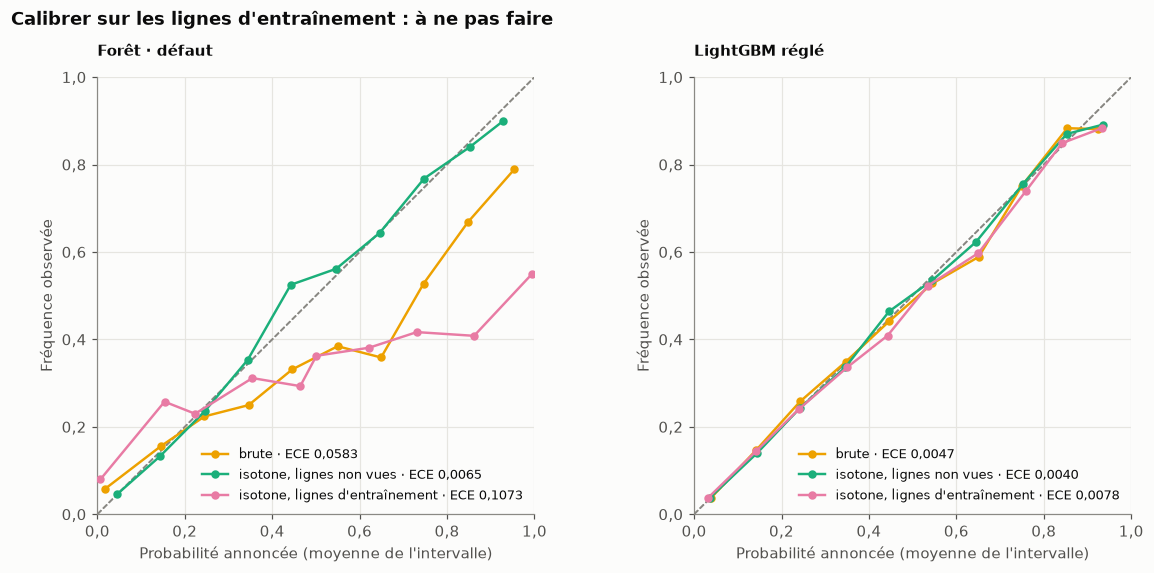

In [17]:
Q85_COLORS = {"brute": viz.COMPOSITION[2], "isotone": viz.COMPOSITION[0],
              "isotone sur le train": viz.COMPOSITION[3]}
Q85_LABELS = {"brute": "brute", "isotone": "isotone, lignes non vues",
              "isotone sur le train": "isotone, lignes d'entraînement"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, name in zip(axes, ["Forêt · défaut", "LightGBM réglé"]):
    for v, color in Q85_COLORS.items():
        ece = q85.loc[f"{name} · {v}", "ECE"]
        viz.reliability(ax, y_train, oof[(name, v)], color=color, ci=False,
                        label=f"{Q85_LABELS[v]} · ECE {viz.fr(f'{ece:.4f}')}")
    ax.set_title(name, fontsize=10)
    ax.legend(loc="lower right", fontsize=8.5)
fig.suptitle("Calibrer sur les lignes d'entraînement : à ne pas faire", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "08_calibrateur_sur_train")
plt.show()

**Réponse Q8.5.** La fonction de calibration a été apprise **dans le train seulement, sur des lignes que le modèle n'avait pas vues** : dans chaque pli extérieur, `CalibratedClassifierCV(cv=5)` redécoupe les lignes d'entraînement en 5, entraîne le modèle sur 4/5 et apprend la fonction sur les prédictions du 1/5 restant. Le pli extérieur, lui, ne sert qu'à mesurer.

- **Jamais sur les lignes qui ont entraîné le modèle** : sur ses propres lignes, un modèle est trop sûr de lui (il les a apprises). La fonction apprend « quand le modèle annonce 95 %, c'est presque toujours vrai », ce qui est faux sur des personnes nouvelles. L'expérience le montre : pour la forêt par défaut, l'ECE passe de 0,058 (brute) à **0,107** : **pire que sans calibration**, contre 0,0065 avec la bonne procédure. Le dégât suit le surapprentissage : modéré pour LightGBM (0,0078 contre 0,0040), nul pour la régression logistique (0,003), dont les scores d'entraînement et de validation se ressemblent (0,566 contre 0,561 à l'étape 5).
- **Jamais sur le test** (slide 43) : la calibration est une étape d'apprentissage ; apprise sur le test, elle ferait de lui une donnée d'entraînement, et la mesure finale de l'étape 10 (ECE, coût au seuil) serait optimiste. Le test ne sert qu'une fois, à la fin, pour mesurer la procédure complète : modèle, calibration, seuil.

### Synthèse de l'étape 8

| Modèle | ECE brute | Plancher (95e c.) | Calibration utile ? | Comptes par pays (z = écart / écart-type) |
|---|---|---|---|---|
| Régression logistique | 0,0059 | 0,0074 | non | exacts (\|z\| ≤ 0,05) |
| LightGBM réglé | 0,0047 | 0,0073 | non | dans le bruit (\|z\| ≤ 0,5) |
| CatBoost réglé | 0,0053 | 0,0070 | non (Platt nuisible) | dans le bruit (\|z\| ≤ 1,04 ; total −1,2 %) |
| Forêt · défaut | 0,0583 | 0,0065 | **oui** (isotone : 0,0065) | |
| Forêt · leaf=10 | 0,0087 | 0,0070 | un peu | **Ouganda +29 %** |

- Les trois candidats sont **déjà calibrés** : l'ECE ne les départage pas, et ajouter une calibration coûterait un peu de PR-AUC et de log-loss pour un gain invisible. On garde leurs **probabilités brutes**.
- Pour la banque centrale, la régression logistique est la plus sûre ; LightGBM et CatBoost restent dans le bruit.
- **Étape 9** : choisir le seuil de KaziPay. Comme les probabilités sont calibrées, le seuil théorique $t^* \approx 0{,}091$ devrait être proche du seuil appris sur les données ; le coût au seuil départagera les candidats.